In [ ]:
# imports
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn import metrics
from sklearn.metrics import f1_score, roc_curve, roc_auc_score
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import RidgeClassifier
from sklearn.preprocessing import StandardScaler

In [ ]:
# import fall_features_noisy.csv
from google.colab import files
uploaded = files.upload()

Saving fall_features_noisy.csv to fall_features_noisy.csv


In [ ]:
df = pd.read_csv("fall_features_noisy.csv")

In [ ]:
X = df.drop("label", axis=1)
y = df["label"]

In [ ]:
# split data into 75% training and 25% testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)

In [ ]:
def evaluate_model(name, y_pred):
  print(f"\n{name}")
  print("Accuracy:", metrics.accuracy_score(y_test, y_pred))
  print("Precision:", metrics.precision_score(y_test, y_pred))
  print("Recall:", metrics.recall_score(y_test, y_pred))
  print("F1 Score:", metrics.f1_score(y_test, y_pred))

In [ ]:
def plot_auc(name, auc_model, fpr, tpr, color=None):
  plt.figure(figsize=(8, 6))
  plt.plot(fpr, tpr, label=f"ROC curve (AUC = {auc_model:.2f})", color=color)
  plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
  plt.xlabel("False Positive Rate")
  plt.ylabel("True Positive Rate (Recall)")
  plt.title("ROC Curve for " + f"\n{name}")
  plt.legend(loc="lower right")
  plt.grid(True)
  plt.show()

In [ ]:
# train logistic regression model
logreg = LogisticRegression(solver='liblinear')
logreg.fit(X_train, y_train)

LogisticRegression(solver='liblinear')

In [ ]:
# predict on the test set
y_pred_logreg = logreg.predict(X_test)

# evaluate the model
evaluate_model("Logistic Regression", y_pred_logreg)

# view the confusion matrix
print("Confusion Matrix:\n", metrics.confusion_matrix(y_test, y_pred_logreg))


Logistic Regression
Accuracy: 0.907563025210084
Precision: 0.9173553719008265
Recall: 0.9446808510638298
F1 Score: 0.9308176100628931
Confusion Matrix:
 [[102  20]
 [ 13 222]]


In [ ]:
y_probs_logreg = logreg.predict_proba(X_test)[:, 1]

In [ ]:
fpr_logreg, tpr_logreg, thresholds_logreg = roc_curve(y_test, y_probs_logreg)

In [ ]:
# find area under the curve
auc_logreg = roc_auc_score(y_test, y_probs_logreg)
print("ROC AUC:", auc_logreg)

ROC AUC: 0.9675967910708057


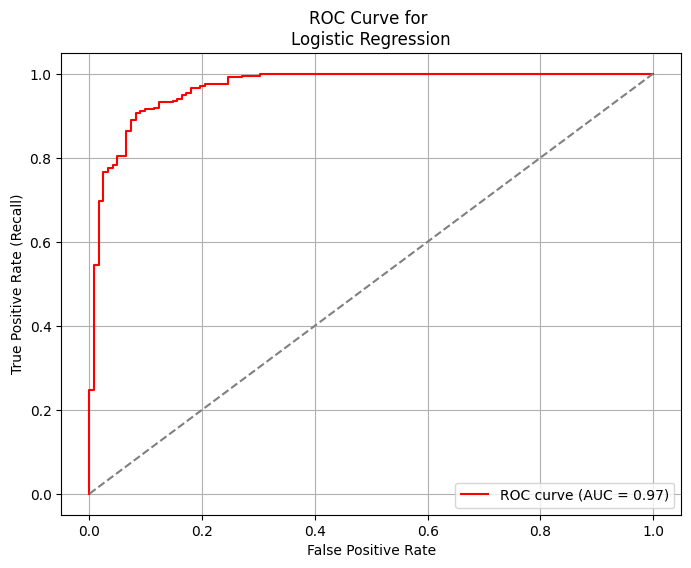

In [ ]:
# plot area under the curve
plot_auc("Logistic Regression", auc_logreg, fpr_logreg, tpr_logreg, color="red")

In [ ]:
# train random forest classifier model
rf = RandomForestClassifier(n_estimators=100, random_state=0)
rf.fit(X_train, y_train)

RandomForestClassifier(random_state=0)

In [ ]:
# predict on the test set
y_pred_rf = rf.predict(X_test)

# evaluate the model
evaluate_model("Random Forest", y_pred_rf)

# view the confusion matrix
print("Confusion Matrix:\n", metrics.confusion_matrix(y_test, y_pred_rf))


Random Forest
Accuracy: 0.907563025210084
Precision: 0.8976377952755905
Recall: 0.9702127659574468
F1 Score: 0.9325153374233128
Confusion Matrix:
 [[ 96  26]
 [  7 228]]


In [ ]:
y_probs_rf = rf.predict_proba(X_test)[:, 1]

In [ ]:
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_probs_rf)

In [ ]:
# find area under the curve
auc_rf = roc_auc_score(y_test, y_probs_rf)
print("Random Forest AUC:", auc_rf)

Random Forest AUC: 0.9507673526334147


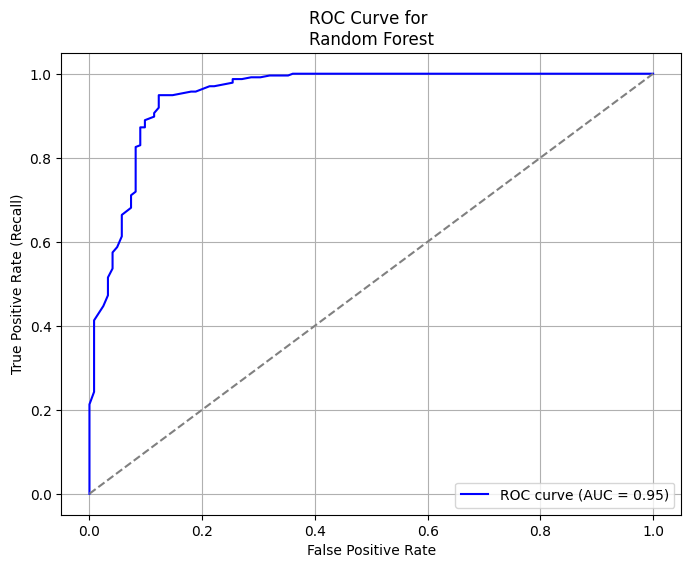

In [ ]:
# plot area under the curve
plot_auc("Random Forest", auc_rf, fpr_rf, tpr_rf, color="blue")

In [ ]:
# train support vector machine model
svm = SVC(kernel='linear', probability=True)
svm.fit(X_train, y_train)

SVC(kernel='linear', probability=True)

In [ ]:
# predict on the test set
y_pred_svm = svm.predict(X_test)

# evaluate the model
evaluate_model("Support Vector Machine", y_pred_svm)

# view the confusion matrix
print("Confusion Matrix:\n", metrics.confusion_matrix(y_test, y_pred_svm))


Support Vector Machine
Accuracy: 0.8991596638655462
Precision: 0.9163179916317992
Recall: 0.9319148936170213
F1 Score: 0.9240506329113924
Confusion Matrix:
 [[102  20]
 [ 16 219]]


In [ ]:
y_probs_svm = svm.predict_proba(X_test)[:, 1]

In [ ]:
fpr_svm, tpr_svm, _ = roc_curve(y_test, y_probs_svm)

In [ ]:
# find area under the curve
auc_svm = roc_auc_score(y_test, y_probs_svm)
print("ROC AUC:", auc_svm)

ROC AUC: 0.9642134635507498


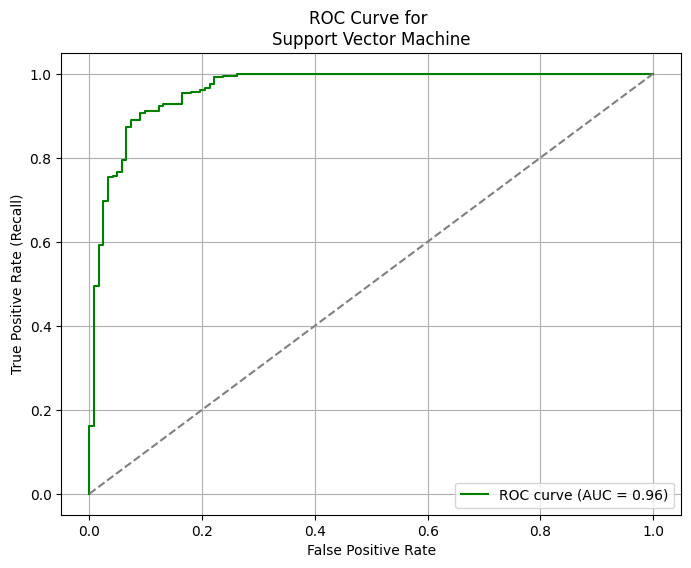

In [ ]:
# plot area under the curve
plot_auc("Support Vector Machine", auc_svm, fpr_svm, tpr_svm, color="green")

In [ ]:
# train k-nearest neighbour model
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

KNeighborsClassifier()

In [ ]:
# predict on the test set
y_pred_knn = knn.predict(X_test)

# evaluate the model
evaluate_model("K-Nearest Neighbour", y_pred_knn)

# view the confusion matrix
print("Confusion Matrix:\n", metrics.confusion_matrix(y_test, y_pred_knn))


K-Nearest Neighbour
Accuracy: 0.9019607843137255
Precision: 0.8846153846153846
Recall: 0.9787234042553191
F1 Score: 0.9292929292929293
Confusion Matrix:
 [[ 92  30]
 [  5 230]]


In [ ]:
y_probs_knn = knn.predict_proba(X_test)[:, 1]

In [ ]:
fpr_knn, tpr_knn, _ = roc_curve(y_test, y_probs_knn)

In [ ]:
# find area under the curve
auc_knn = roc_auc_score(y_test, y_probs_knn)
print("ROC AUC:", auc_knn)

ROC AUC: 0.9252877572375305


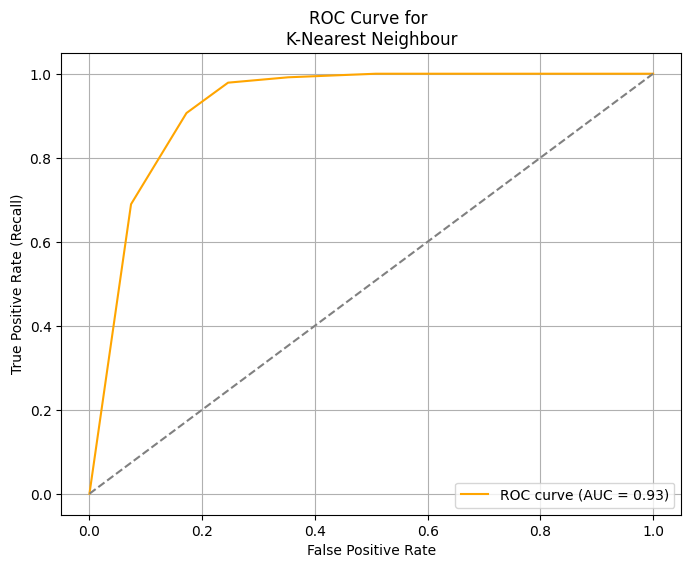

In [ ]:
# plot area under the curve
plot_auc("K-Nearest Neighbour", auc_knn, fpr_knn, tpr_knn, color="orange")

In [ ]:
# train ridge classifier model
ridge = RidgeClassifier()
ridge.fit(X_train, y_train)

RidgeClassifier()

In [ ]:
# predict on the test set
y_pred_ridge = ridge.predict(X_test)

# evaluate the model
evaluate_model("Ridge Classifier", y_pred_ridge)

# view the confusion matrix
print("Confusion Matrix:\n", metrics.confusion_matrix(y_test, y_pred_ridge))


Ridge Classifier
Accuracy: 0.9215686274509803
Precision: 0.9123505976095617
Recall: 0.9744680851063829
F1 Score: 0.9423868312757202
Confusion Matrix:
 [[100  22]
 [  6 229]]


In [ ]:
y_scores_ridge = ridge.decision_function(X_test)

In [ ]:
fpr_ridge, tpr_ridge, _ = roc_curve(y_test, y_scores_ridge)

In [ ]:
# find area under the curve
auc_ridge = roc_auc_score(y_test, y_scores_ridge)
print("ROC AUC:", auc_ridge)

ROC AUC: 0.9667945587722359


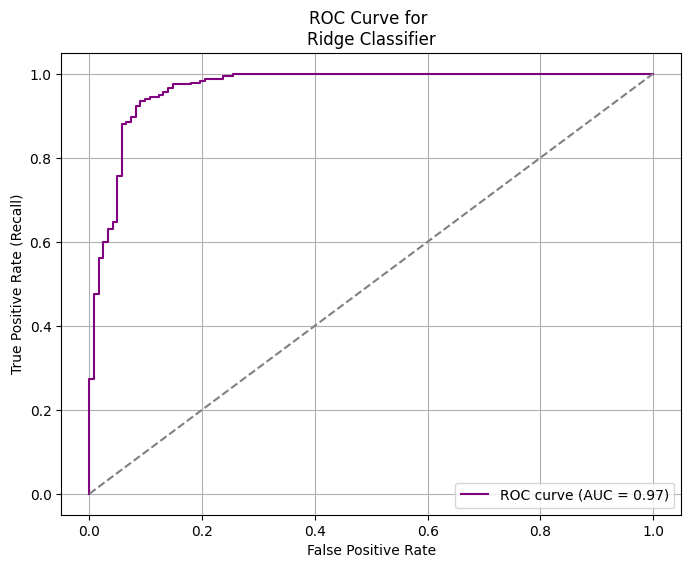

In [ ]:
# plot area under the curve
plot_auc("Ridge Classifier", auc_ridge, fpr_ridge, tpr_ridge, color="purple")

In [ ]:
# store results of each model
results = []

def store_results(name, y_pred):
  results.append({
      "Model": name,
      "Accuracy": metrics.accuracy_score(y_test, y_pred),
      "Precision": metrics.precision_score(y_test, y_pred),
      "Recall": metrics.recall_score(y_test, y_pred),
      "F1 Score": metrics.f1_score(y_test, y_pred)
  })

store_results("Logistic Regression", y_pred_logreg)
store_results("Random Forest", y_pred_rf)
store_results("Support Vector Machine", y_pred_svm)
store_results("K-Nearest Neighbour", y_pred_knn)
store_results("Ridge Classifier", y_pred_ridge)

In [ ]:
# print results
results_df = pd.DataFrame(results)
print(results_df)

                    Model  Accuracy  Precision    Recall  F1 Score
0     Logistic Regression  0.907563   0.917355  0.944681  0.930818
1           Random Forest  0.907563   0.897638  0.970213  0.932515
2  Support Vector Machine  0.899160   0.916318  0.931915  0.924051
3     K-Nearest Neighbour  0.901961   0.884615  0.978723  0.929293
4        Ridge Classifier  0.921569   0.912351  0.974468  0.942387


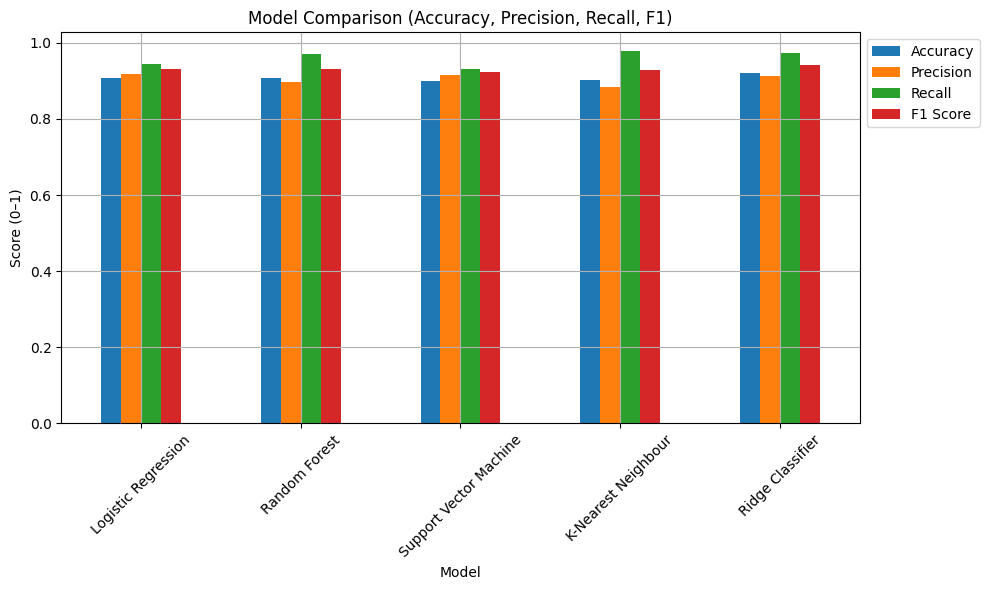

In [ ]:
# plot results
results_df.set_index("Model").plot(kind="bar", figsize=(10,6))

plt.title("Model Comparison (Accuracy, Precision, Recall, F1)")
plt.ylabel("Score (0–1)")
plt.xticks(rotation=45)
plt.grid(True)

plt.legend(loc='upper left', bbox_to_anchor=(1,1))
plt.tight_layout()

plt.show()

In [ ]:
# highlight best model
best_model = results_df.loc[results_df["F1 Score"].idxmax()]
print("\nBest Model Based on F1 Score:")
print(best_model)


Best Model Based on F1 Score:
Model        Ridge Classifier
Accuracy             0.921569
Precision            0.912351
Recall               0.974468
F1 Score             0.942387
Name: 4, dtype: object


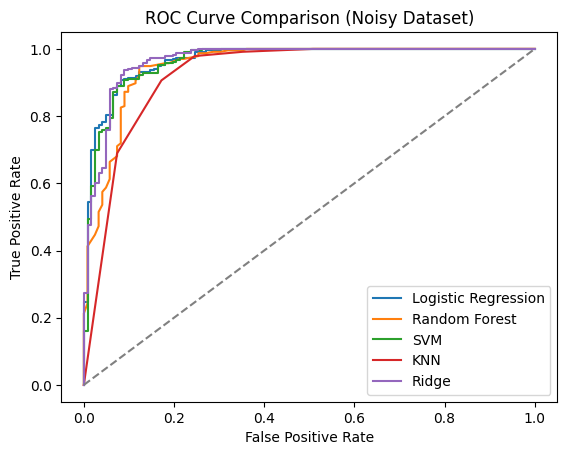

In [ ]:
plt.figure()

plt.plot(fpr_logreg, tpr_logreg, label="Logistic Regression")
plt.plot(fpr_rf, tpr_rf, label="Random Forest")
plt.plot(fpr_svm, tpr_svm, label="SVM")
plt.plot(fpr_knn, tpr_knn, label="KNN")
plt.plot(fpr_ridge, tpr_ridge, label="Ridge")

plt.plot([0,1],[0,1],'--',color='gray')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison (Noisy Dataset)")
plt.legend()
plt.show()